In [1]:
from torchvision import datasets, transforms

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_data = datasets.MNIST(root="~/.cache/", transform=transform, train=True, download=True)
test_data = datasets.MNIST(root="~/.cache/", transform=transform, train=False)
print(train_data[0][0].shape)

torch.Size([1, 28, 28])


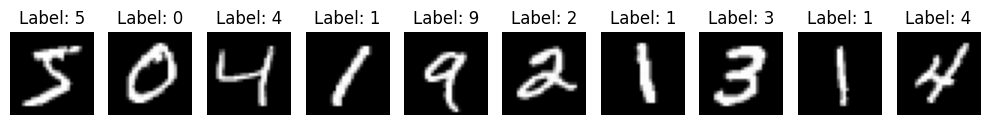

In [2]:
import matplotlib.pyplot as plt

# 遍历前10张图片
fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = train_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from quantizer import VectorQuantizer


class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),   # (28x28) → (14x14)
            nn.ReLU(),
            nn.Conv2d(16, 64, kernel_size=4, stride=2, padding=1),  # (14x14) → (7x7)
            nn.ReLU(),
            nn.Conv2d(64, 16, kernel_size=4, stride=2, padding=1),  # (7x7) → (4x4)
        )

    def forward(self, x):
        return self.encoder(x)  # (B, 16, 3, 3)


class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(16, 64, kernel_size=4, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 16, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),
        )

    def forward(self, x):
        return self.decoder(x)  # (B, 1, 28, 28)


class VQVAE(nn.Module):
    def __init__(self, n_e, e_dim):
        super().__init__()
        self.encoder = Encoder()
        self.quantizer = VectorQuantizer(n_e, e_dim)
        self.decoder = Decoder()

    def forward(self, x: torch.Tensor):
        # (B, C, H, W)
        z = self.encoder(x)
        z_q, indices, q_loss = self.quantizer(z)
        x_q = self.decoder(z_q)

        return x_q, indices, q_loss
    
    def encode(self, x: torch.Tensor):
        # (B, C, H, W)
        z = self.encoder(x)
        z_q, *_ = self.quantizer(z)
        return z_q
    
    def decode(self, z_q: torch.Tensor):
        # (B, C, H, W)
        x_q = self.decoder(z_q)
        return x_q

In [7]:
vqvae = VQVAE(n_e=128, e_dim=9)

x: torch.Tensor = train_data[0][0]
x = x.unsqueeze(0)  # 添加batch维度

x_q, indices, vq_loss = vqvae(x) 
print(x_q.shape)
print(indices.shape) # use 16 tokens to encode one image

z_q = vqvae.encode(x)
print(z_q.shape)



torch.Size([1, 1, 28, 28])
torch.Size([1, 16])
torch.Size([1, 16, 3, 3])


In [9]:
vqvae = VQVAE(n_e=128, e_dim=9)

dataloader = torch.utils.data.DataLoader(train_data, batch_size=512, shuffle=True, num_workers=4)
optimizer = torch.optim.Adam(vqvae.parameters(), lr=1e-3)
epochs = 40

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


vqvae.to(device).train()
for epoch in range(epochs):
    for img, _ in dataloader:
        img = img.to(device)

        x_q, _, q_loss = vqvae(img)
        loss = F.mse_loss(x_q, img) + q_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item():.4f}")




Epoch 1/40, Loss: 0.3657
Epoch 2/40, Loss: 0.3683
Epoch 3/40, Loss: 0.2292
Epoch 4/40, Loss: 0.1887
Epoch 5/40, Loss: 0.1615
Epoch 6/40, Loss: 0.1600
Epoch 7/40, Loss: 0.1640
Epoch 8/40, Loss: 0.1479
Epoch 9/40, Loss: 0.1480
Epoch 10/40, Loss: 0.1508
Epoch 11/40, Loss: 0.1392
Epoch 12/40, Loss: 0.1332
Epoch 13/40, Loss: 0.1298
Epoch 14/40, Loss: 0.1410
Epoch 15/40, Loss: 0.1343
Epoch 16/40, Loss: 0.1269
Epoch 17/40, Loss: 0.1289
Epoch 18/40, Loss: 0.1354
Epoch 19/40, Loss: 0.1246
Epoch 20/40, Loss: 0.1241
Epoch 21/40, Loss: 0.1313
Epoch 22/40, Loss: 0.1252
Epoch 23/40, Loss: 0.1357
Epoch 24/40, Loss: 0.1233
Epoch 25/40, Loss: 0.1288
Epoch 26/40, Loss: 0.1194
Epoch 27/40, Loss: 0.1159
Epoch 28/40, Loss: 0.1218
Epoch 29/40, Loss: 0.1201
Epoch 30/40, Loss: 0.1176
Epoch 31/40, Loss: 0.1184
Epoch 32/40, Loss: 0.1201
Epoch 33/40, Loss: 0.1142
Epoch 34/40, Loss: 0.1167
Epoch 35/40, Loss: 0.1190
Epoch 36/40, Loss: 0.1106
Epoch 37/40, Loss: 0.1175
Epoch 38/40, Loss: 0.1149
Epoch 39/40, Loss: 0.

[[ 47  34   6  51  22  35  13  18  99 122  54 115  79   7 117  34]
 [ 78  35  12  23 109  25  80  96 123 124  45 110  28  51 117  34]
 [107  70  29 101 102  34 101 122 101  59  13  36  97  88  60  16]
 [113  48  94  93  16 105  13  20   1  25  87  72 110  57  71  73]
 [ 47   5  19  49  82  85  52 115  61  97  87  36  34  90  60  73]
 [ 89  24 109   7  78  16  46 115  37  59  47  90  92  37  76  73]
 [113   5 104  49  62 116  13  43  38  67  87  36  22 125  26  57]
 [ 57  77  61  72 112  77 105  28  99   8  54  90 126  15  51  10]
 [113  24   6 120  62 116  13  43  38 122  87  36  27 125  60  73]
 [113  48 109  58 125  35  76  85 119  59  51  51  12   7  71  73]]


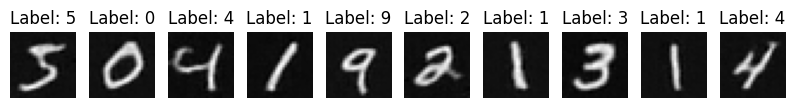

In [11]:
# 遍历前10张图片
x = torch.vstack([train_data[i][0] for i in range(10)]).unsqueeze(1).to(device)
x_q, ids, vq_loss = vqvae(x)
x_q = x_q.cpu().detach()
x_p = vqvae.decode(vqvae.encode(x)).cpu().detach()

print(ids.cpu().numpy())

fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = x_p[i], train_data[i][1]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴